# 02 · 真实人脸表情识别模型训练验证

从Kaggle下载的AffectNet压缩图像数据出发，构造四类偏差，每类11个比例点、3次重复，共训练132个ResNet50，每个20轮；另做3次配对重加权对照。

本文件记录数据划分、采样规则、训练配置、已完成的训练日志、分组召回率和真实模型对照结果。图片为96×96，输入网络时调整至224×224；下载包的数据划分、采样规模和人口属性标注与原文不完全相同。

In [1]:
# 读取实验协议与数据清单；manifest哈希用于确认分析的是训练时同一批图片。
from pathlib import Path
import sys, json, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd() if (Path.cwd()/'configs').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/'src'))
from appendix_a.data import CLASSES, GENDERS, required_counts, validate_manifest, sha256_file
config_path=ROOT/'configs/appendix_a_kaggle.json'
config=json.loads(config_path.read_text())
# 结果目录相对于当前项目定位。
results=ROOT/'results/appendixA_kaggle'
provenance=json.loads((results/'data_provenance.json').read_text())
display(provenance)
assert provenance['original_paper_data_match'] is False
assert provenance['smoke_test_only'] is False
manifest_path=results/'input_manifest.csv'
assert sha256_file(manifest_path)==provenance['manifest_sha256']
manifest=validate_manifest(pd.read_csv(manifest_path),check_files=False)
display(manifest.groupby('split').size().rename('本次实际使用的图片数'))


{'dataset': 'fatihkgg/affectnet-yolo-format',
 'version': 2,
 'url': 'https://www.kaggle.com/datasets/fatihkgg/affectnet-yolo-format',
 'archive_sha256': '883521d22d3f80b8b3da3b221dfbf2f173f186fd9dc380c028cad1f5cbae2c66',
 'fairface_model_sha256': '37f2e74c0e7da196f8edd7dae0c88cffdbef7923beebebcc27381f0ad0fdb2c1',
 'fairface_model_file': 'fairface_resnet34_7race_20190809.pt',
 'demographics': 'FairFace predictions, not self-reported identity',
 'crop_method': 'Kaggle provided 96px crops; no MMOD recropping',
 'original_paper_data_match': False,
 'smoke_test_only': False,
 'raw_7class_rows': 22316,
 'label_conflict_rows_removed': 0,
 'duplicate_rows_removed': 228,
 'rows_after_dedup': 22088,
 'splits_after_dedup': {'train': 14903, 'validation': 4764, 'test': 2421},
 'subject_identity_available': False,
 'exact_hash_dedup_is_not_subject_disjointness': True,
 'manifest_sha256': '868a06bb475555ce3990e074b1973f3809d5cf1d0f022a11654a7d24e2ae03d4'}

split
test      2421
train    14903
Name: 本次实际使用的图片数, dtype: int64

## 1. 数据来源、去重和人口属性

图像包包含25,262张96×96图片、8种表情。按七类任务排除contempt后，根据文件SHA256检查重复和标签冲突，优先保留测试与验证分割中的文件。

最终训练14,903张、验证4,764张、测试2,421张。验证集未并入训练，也不用于挑选模型。FairFace 20190809 7-race ResNet34为图片预测人口属性，按图片路径关联表情标签。性别是模型预测的二元表观类别；没有主体ID，文件去重不能保证主体互斥。

In [2]:
# 检查按性别和表情划分的样本数；测试集在所有训练比例下保持不变。
train_counts=pd.read_csv(results/'source_training_counts.csv',index_col=0).reindex(index=GENDERS,columns=CLASSES)
test_counts=pd.read_csv(results/'test_counts.csv',index_col=0).reindex(index=GENDERS,columns=CLASSES)
display(Markdown('**FairFace 预测后的训练支持量**'));display(train_counts)
display(Markdown('**保留测试集支持量**'));display(test_counts)
assert train_counts.to_numpy().sum()==14903
assert test_counts.to_numpy().sum()==2421
assert (test_counts>0).all().all()
assert train_counts.min(axis=0).astype(int).to_dict()==config['class_totals']


**FairFace 预测后的训练支持量**

,angry,disgust,fear,happy,neutral,sad,surprise
gender,,,,,,,
Female,555,999,967,1261,830,822,1261
Male,1758,1199,973,892,784,1062,1540


**保留测试集支持量**

,angry,disgust,fear,happy,neutral,sad,surprise
gender,,,,,,,
Female,94,153,151,236,122,120,195
Male,288,174,166,163,128,158,273


## 2. 四类偏差与采样规则

每类目标数量取训练集中男女样本数量的较小值，以支持无放回采样。使用整数算术计算 `floor(n*q)`。

1. 所有类别同时改变男女比例。
2. 只改变happy类。
3. happy与angry反向改变。
4. happy与angry同向改变。

每个设置使用三次采样与初始化；所有比例点遵循相同的类别规模规则。

In [3]:
# 核对4种实验×11个比例点×3次重复，并展示端点需要的采样数量。
plan=pd.read_csv(results/'plan.csv')
assert len(plan)==132
assert plan[['experiment','step','repetition']].drop_duplicates().shape[0]==132
assert sorted(plan['step'].unique())==list(range(11))
display(plan.groupby('experiment').agg(runs=('repetition','size'),min_train=('n_train','min'),max_train=('n_train','max')))
for exp in [1,2,3,4]:
    display(Markdown(f'**实验 {exp}：q=0 与 q=1 的计数**'))
    display(required_counts(exp,0,config['class_totals']))
    display(required_counts(exp,10,config['class_totals']))


,runs,min_train,max_train
experiment,,,
1,33,6273,6280
2,33,6275,6276
3,33,6275,6277
4,33,6275,6277


**实验 1：q=0 与 q=1 的计数**

,angry,disgust,fear,happy,neutral,sad,surprise
Female,0,0,0,0,0,0,0
Male,555,999,967,892,784,822,1261


,angry,disgust,fear,happy,neutral,sad,surprise
Female,555,999,967,892,784,822,1261
Male,0,0,0,0,0,0,0


**实验 2：q=0 与 q=1 的计数**

...

,angry,disgust,fear,happy,neutral,sad,surprise
Female,555,499,483,0,392,411,630
Male,0,499,483,892,392,411,630


,angry,disgust,fear,happy,neutral,sad,surprise
Female,0,499,483,892,392,411,630
Male,555,499,483,0,392,411,630


**实验 4：q=0 与 q=1 的计数**

,angry,disgust,fear,happy,neutral,sad,surprise
Female,0,499,483,0,392,411,630
Male,555,499,483,892,392,411,630


,angry,disgust,fear,happy,neutral,sad,surprise
Female,555,499,483,892,392,411,630
Male,0,499,483,0,392,411,630


## 3. 训练配置与日志

预训练ResNet50、七类线性头，全网络微调20轮；1cycle学习率计划，最高学习率1e-4。使用ImageNet-1K V1初始化、AdamW、batch=256、weight_decay=0.01、ImageNet归一化、随机水平翻转及AMP。

各模型采用相同测试集，只评估最后一轮。每轮保存损失、训练准确率及恢复状态；配置、数据和结果文件记录SHA256。下面展示已完成配置和逐轮日志。

In [4]:
# 逐个读取完成标记；展示一个模型的配置和20轮训练日志作为记录示例。
completed=[]
for path in sorted(results.glob('exp*_q*_rep*/complete.json')):
    item=json.loads(path.read_text())
    assert item['epochs']==20 and item['smoke_test_only'] is False
    completed.append(item)
print(f'真实完成：{len(completed)} / 132')
print('状态：', '完整网格' if len(completed)==132 else 'PARTIAL，仍有配置未完成')
if completed:
    first=results/completed[0]['run']
    run=json.loads((first/'run.json').read_text())
    display({k:run[k] for k in ['torch','torchvision','cuda','gpu','epochs','batch_size','max_lr','manifest_sha256','pretrained_sha256','original_paper_data_match']})
    history=pd.read_csv(first/'history.csv')
    assert history.epoch.tolist()==list(range(1,21))
    display(history)


真实完成：132 / 132
状态： 完整网格


{'torch': '2.6.0+cu124',
 'torchvision': '0.21.0+cu124',
 'cuda': '12.4',
 'gpu': 'NVIDIA GeForce RTX 3090 Ti',
 'epochs': 20,
 'batch_size': 256,
 'max_lr': 0.0001,
 'manifest_sha256': '868a06bb475555ce3990e074b1973f3809d5cf1d0f022a11654a7d24e2ae03d4',
 'pretrained_sha256': '0676ba61b6795bbe1773cffd859882e5e297624d384b6993f7c9e683e722fb8a',
 'original_paper_data_match': False}

,epoch,train_loss,train_accuracy,lr,seconds,rows
0,1,1.940408,0.189968,1.051538e-05,7.136903,6280
1,2,1.744108,0.362420,2.829275e-05,6.115427,6280
2,3,1.365616,0.500796,5.250602e-05,6.126566,6280
3,4,0.952695,0.659713,7.658192e-05,6.085254,6280
4,5,0.572006,0.803503,9.398447e-05,6.058032,6280
5,6,0.294092,0.909873,9.999799e-05,5.991728,6280
6,7,0.147923,0.959236,9.864457e-05,6.176731,6280
7,8,0.084318,0.980414,9.485193e-05,5.991165,6280
8,9,0.046271,0.989968,8.881023e-05,5.998884,6280
9,10,0.027796,0.993790,8.082243e-05,6.362510,6280


## 4. 从混淆矩阵重算召回率

每个性别与表情的 `recall=TP/该组该类测试样本数`，宏平均为七类召回率的算术平均。混淆矩阵维度依次为性别、真实类别、预测类别。

检查配置数量、20轮日志、采样计数、固定测试支持量，以及保存召回率与混淆矩阵是否一致。

In [5]:
# 使用当前Notebook的Python执行验证脚本，重新核算混淆矩阵和召回率。
cmd=[sys.executable,str(ROOT/'scripts/appendix_a/verify_results.py'),'--config',str(config_path)]
# 完整网格按132项严格核验；缺项时验证脚本会报错。
if len(completed)==132:cmd.append('--require-complete')
result=subprocess.run(cmd,cwd=ROOT,text=True,capture_output=True,check=True)
print(result.stdout)


{
  "verified_runs": 132,
  "expected_runs": 132,
  "complete": true,
  "epochs_per_run": 20,
  "recall_entries_recomputed": 2112,
  "scope": "Kaggle modified-data real-image experiment, not original paper AffectNet",
  "all_hashes_counts_histories_and_recalls_match": true
}



## 5. 真实图像召回率曲线

曲线来自模型在保留测试集上的预测。同一比例点按三个种子取均值，阴影为种子间样本标准差，不是置信区间。完整结果包含四组数据指标和男女分表情召回率。

132/132 real runs summarized; complete=True



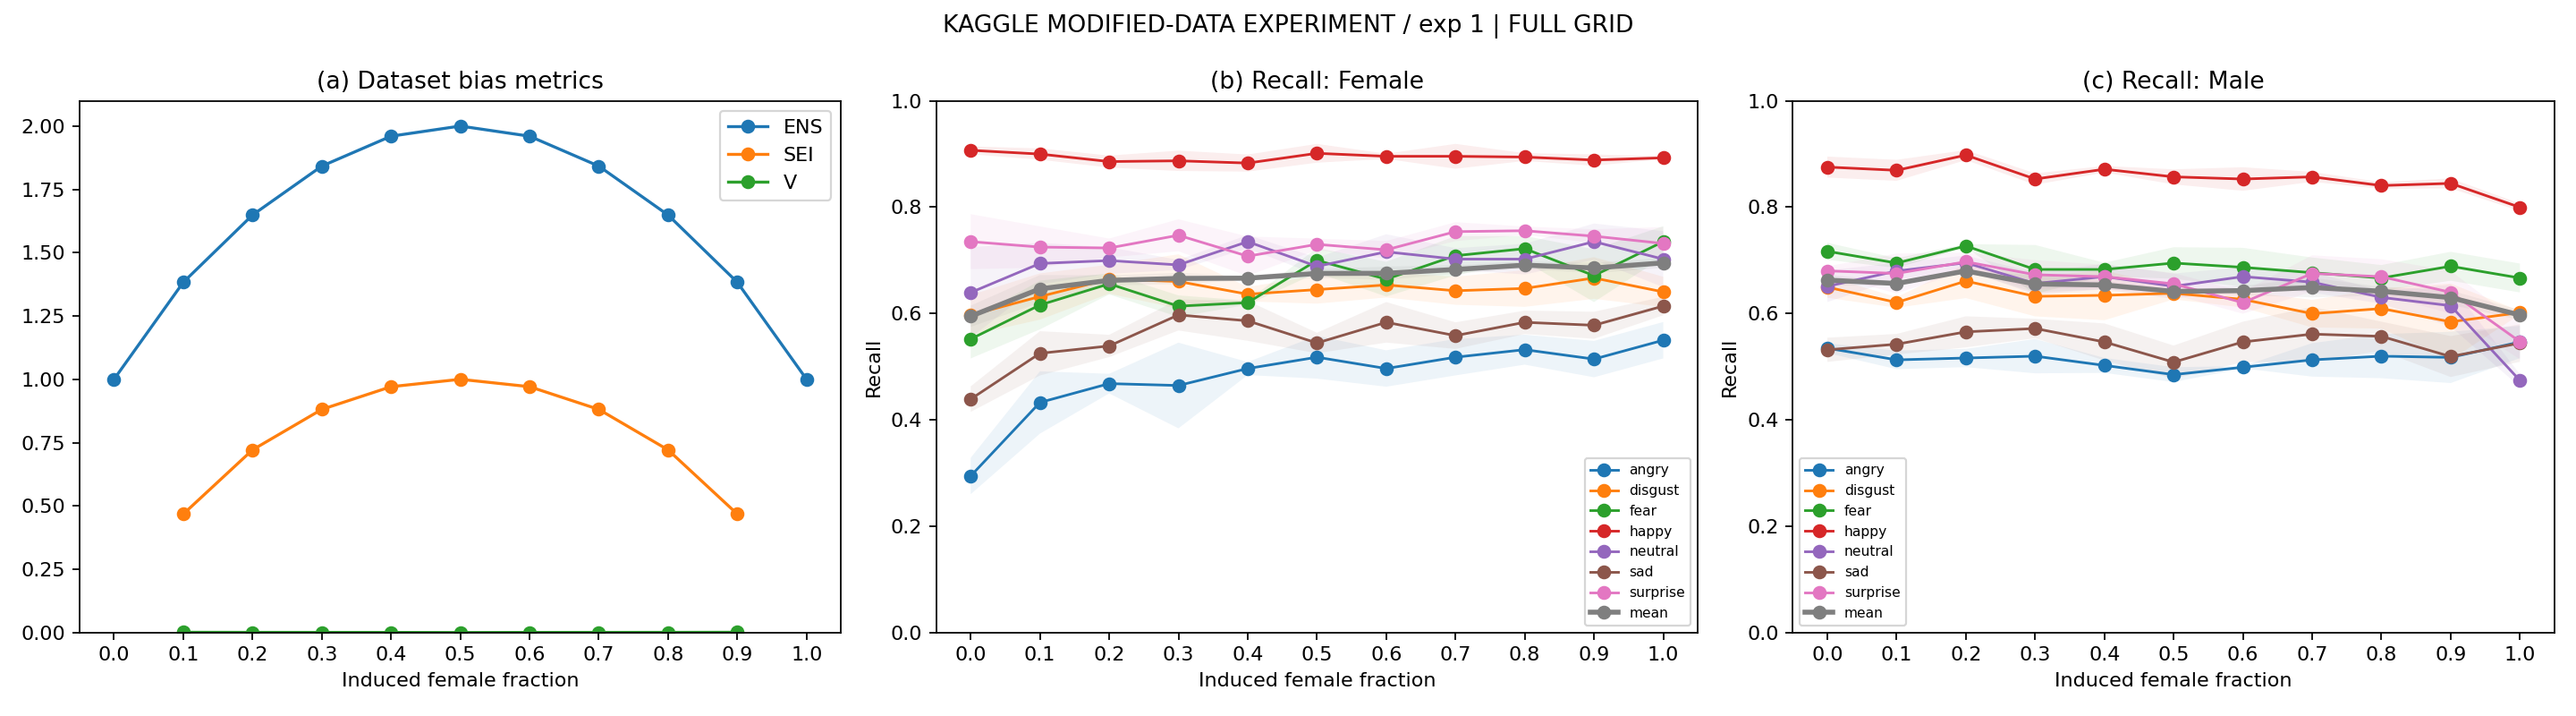

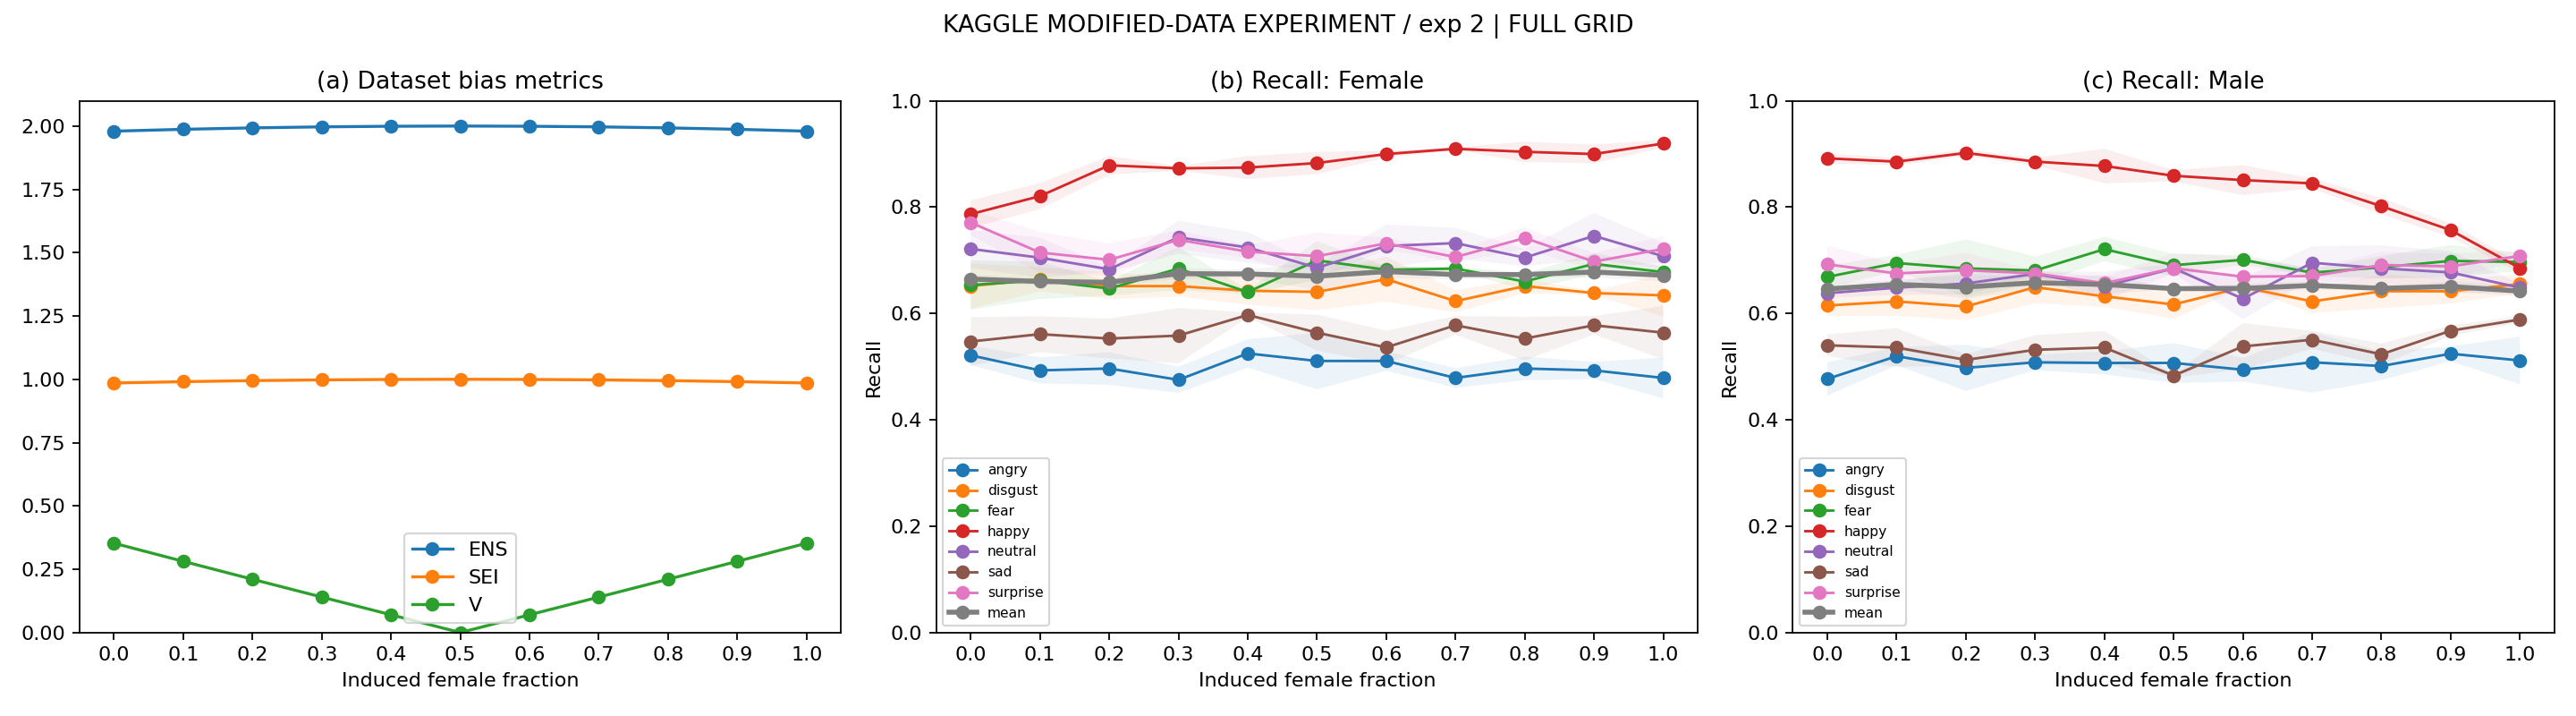

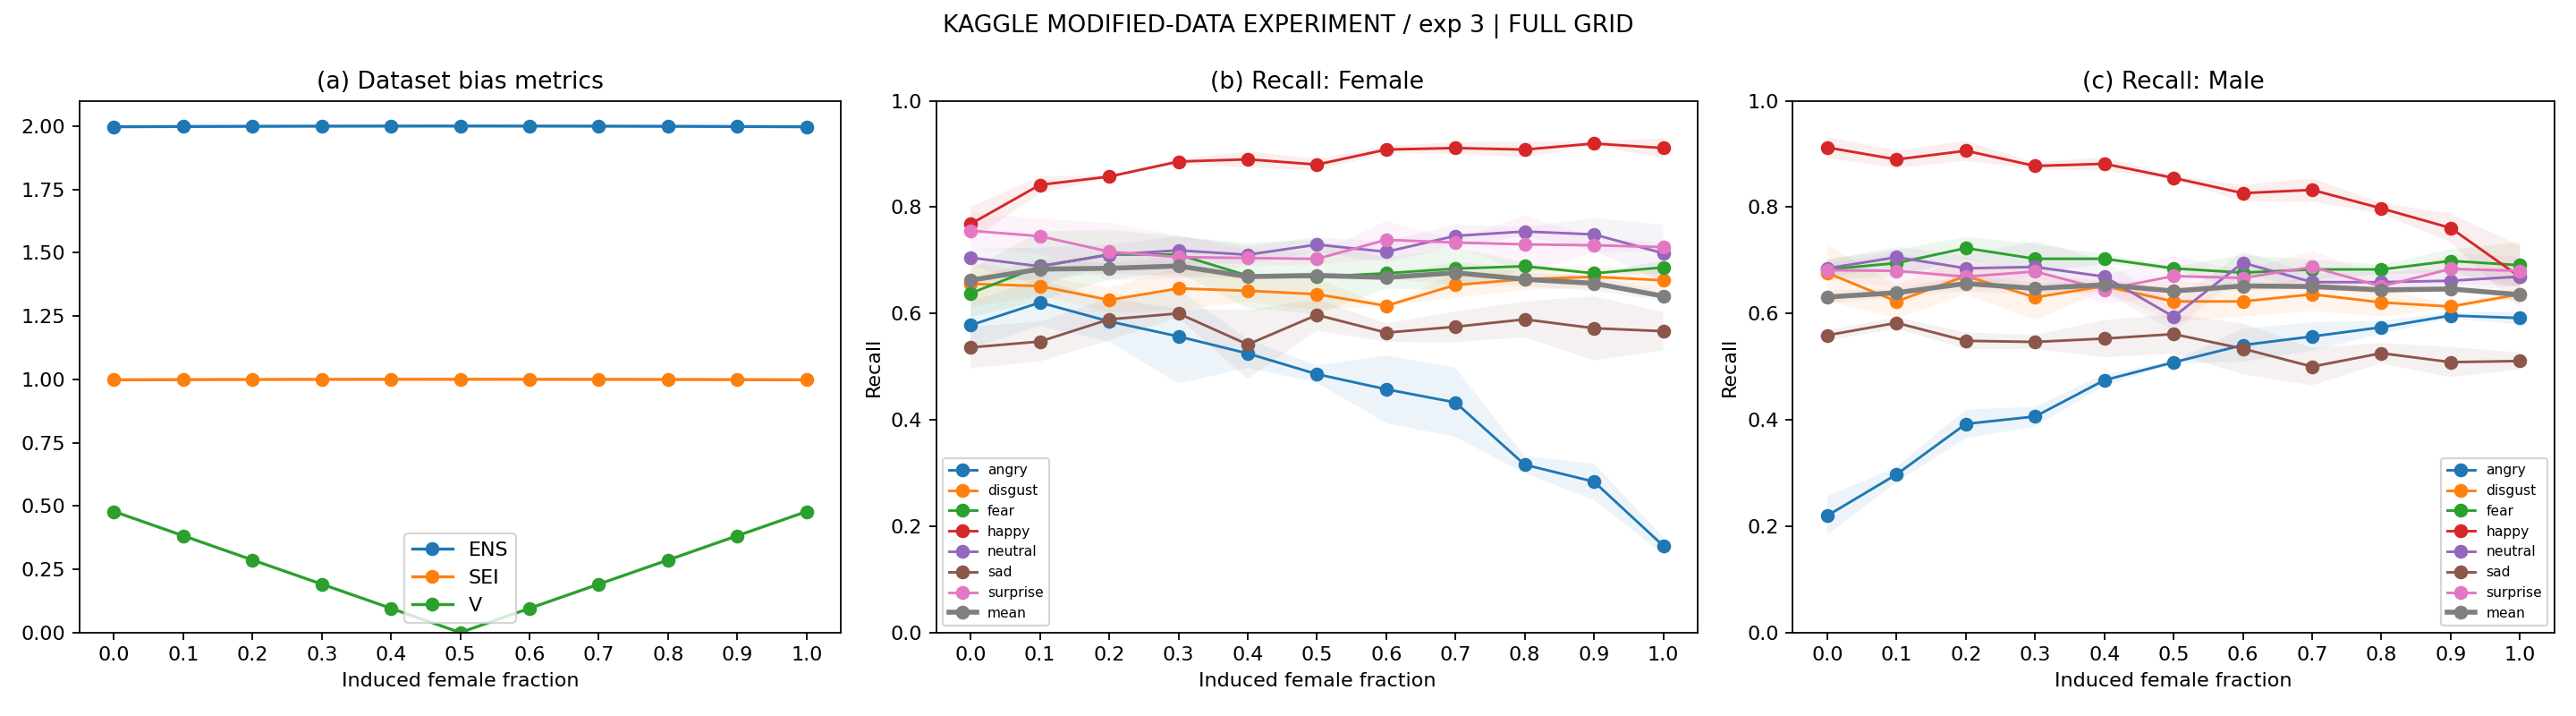

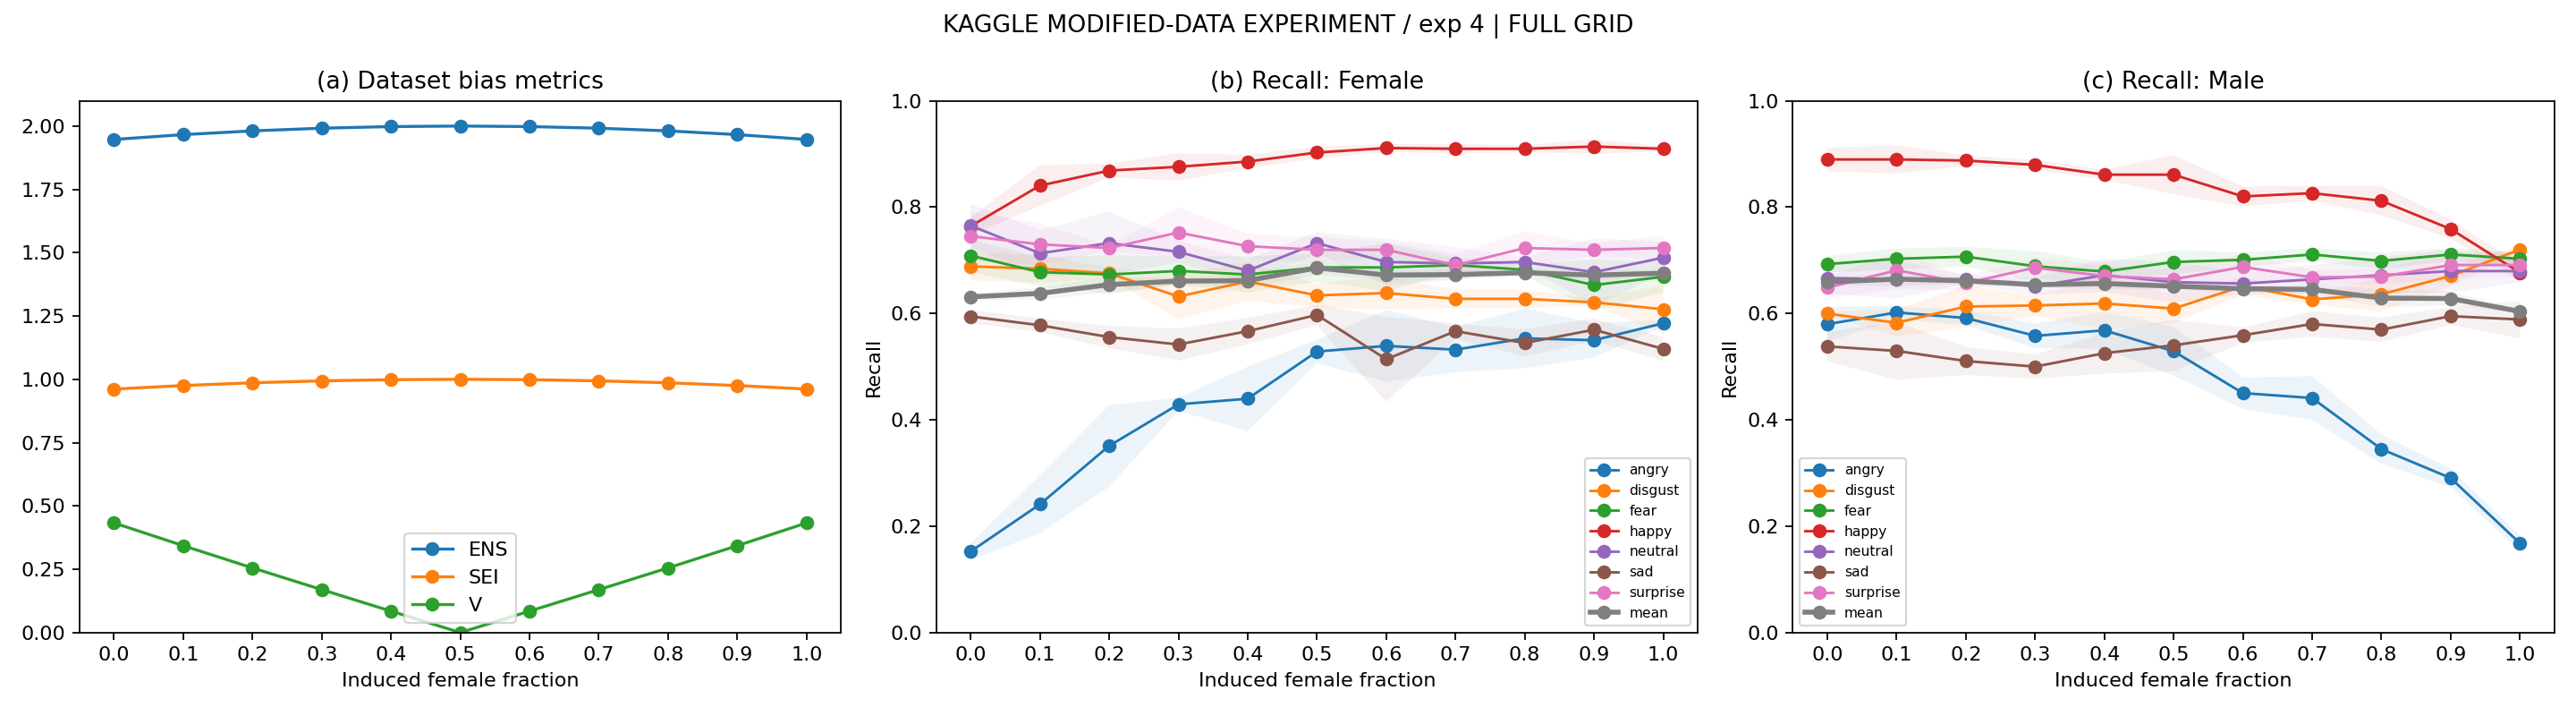

,experiment,fraction,gender,label,mean,std,count
0,1,0.0,Female,angry,0.294326,0.034197,3
3,1,0.0,Female,happy,0.906780,0.007339,3
4,1,0.0,Female,mean,0.594744,0.020030,3
8,1,0.0,Male,angry,0.534722,0.009187,3
11,1,0.0,Male,happy,0.875256,0.019721,3
...,...,...,...,...,...,...,...
691,4,1.0,Female,happy,0.909605,0.004893,3
692,4,1.0,Female,mean,0.675601,0.006075,3
696,4,1.0,Male,angry,0.167824,0.014456,3
699,4,1.0,Male,happy,0.676892,0.015439,3


In [6]:
# 汇总三个种子的真实测试结果；阴影为种子间标准差。
result=subprocess.run([sys.executable,str(ROOT/'scripts/appendix_a/summarize.py'),'--config',str(config_path)],cwd=ROOT,text=True,capture_output=True,check=True)
print(result.stdout)
for exp in [1,2,3,4]:
    figure=results/f'figure_{8+exp:02d}_recall.png'
    if figure.exists():display(Image(filename=str(figure)))
if (results/'recall_summary.csv').exists():
    summary=pd.read_csv(results/'recall_summary.csv')
    display(summary[(summary.fraction.isin([0,.5,1]))&(summary.label.isin(['happy','angry','mean']))])


## 6. 配对重加权对照

固定实验2中q=.1的子集，额外训练三个模型。与各自普通训练基线保持相同样本、初始化种子、优化器、20轮和测试集，只改变损失中的群体×类别权重。

权重先按cap=5截断，再按类别归一，保持类别总权重；cap在测试前固定。报告男女高兴类和宏平均召回率、准确率及有效样本量。

{
  "verified_real_mitigation_models": 3,
  "expected": 3,
  "complete": true,
  "same_subsets_initializations_and_test_sets": true,
  "cap_predeclared": 5,
  "test_used_for_cap_selection": false
}



,method,gender,label,mean,std,count
3,ERM,Female,happy,0.820621,0.024464,3
4,ERM,Female,mean,0.660118,0.005983,3
11,ERM,Male,happy,0.885481,0.007084,3
12,ERM,Male,mean,0.654580,0.008356,3
19,Reweighted,Female,happy,0.830508,0.014678,3
20,Reweighted,Female,mean,0.666526,0.008280,3
27,Reweighted,Male,happy,0.862986,0.009371,3
28,Reweighted,Male,mean,0.648461,0.008580,3


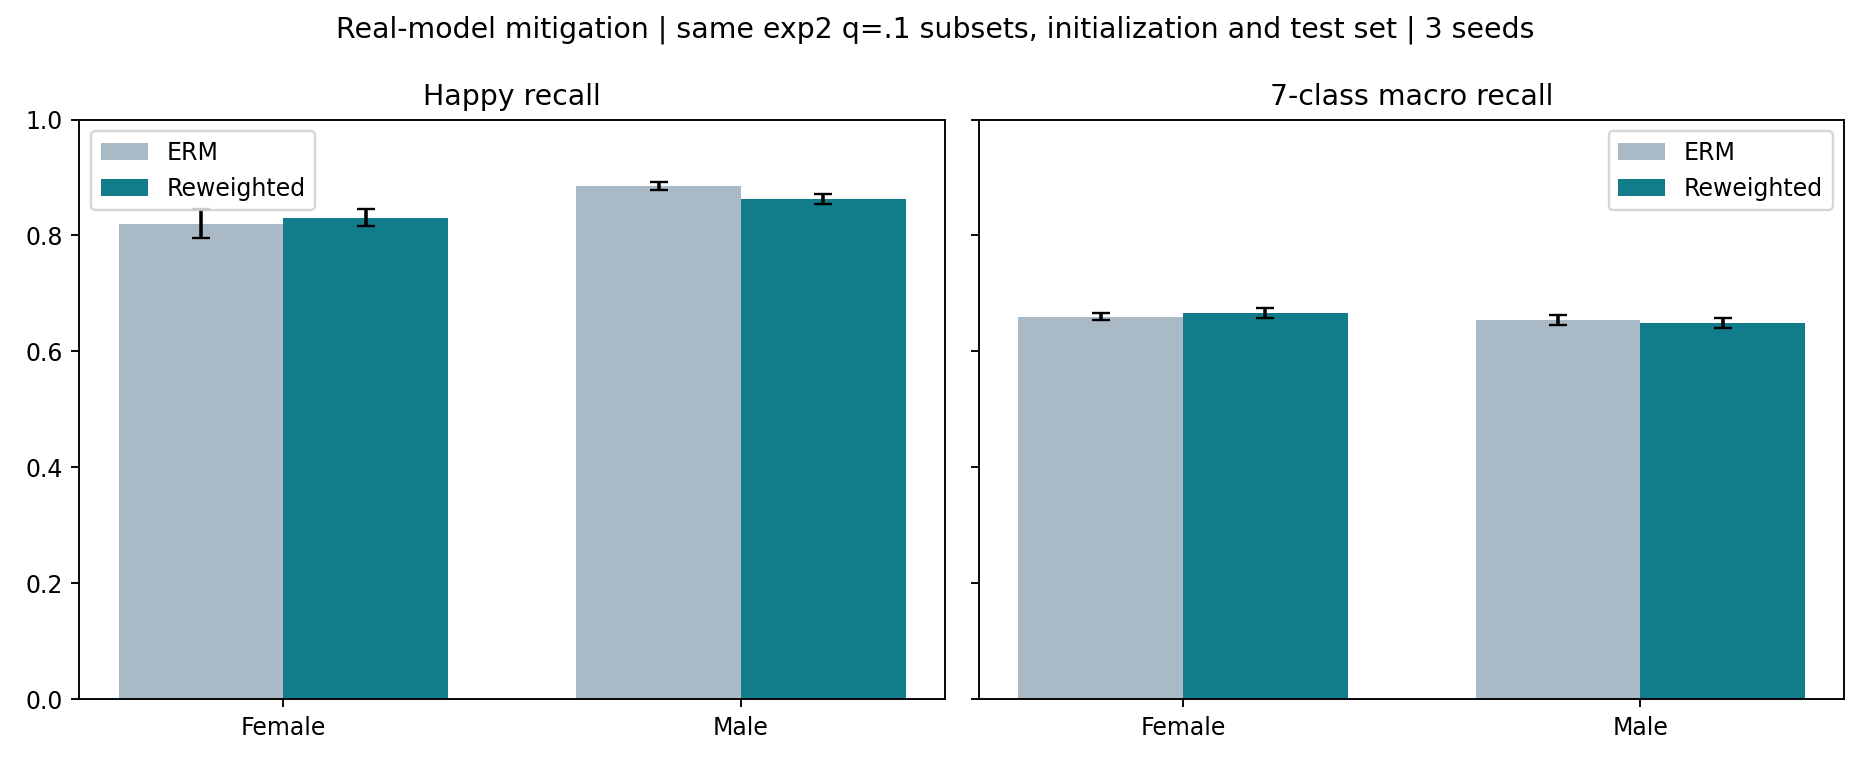

In [7]:
# 配对比较只改变损失权重的三个模型，同时查看男女两组的收益和代价。
mitigation=ROOT/'results/appendixA_mitigation'
if (mitigation/'FINISHED.json').exists():
    checked=subprocess.run([sys.executable,str(ROOT/'scripts/appendix_a/verify_mitigation.py'),'--require-complete'],cwd=ROOT,text=True,capture_output=True,check=True)
    print(checked.stdout)
    paired=pd.read_csv(mitigation/'summary.csv')
    display(paired[paired.label.isin(['happy','mean'])])
    display(Image(filename=str(ROOT/'results/figures/appendixA_real_mitigation.png')))
else:
    print('真实模型重加权对照尚未全部完成；不显示假定收益。')


## 7. 已完成的模型推理复验

导出实验1、q=.5、种子0的均衡模型，在同一批2,421张真实测试图片上再次执行推理。权重、测试清单和预期混淆矩阵记录SHA256，下面为保存的推理结果。

In [8]:
# 读取均衡模型的独立推理结果；要求测试图像数与保存的混淆矩阵一致。
demo=ROOT/'results/appendixA_demo/evaluation.json'
if demo.exists():
    replay=json.loads(demo.read_text());display(replay)
    assert replay['real_test_images']==2421
    assert replay['original_paper_data_match'] is False
    if replay['device']=='cuda':assert replay['confusion_matches_saved'] is True
else:
    print('快速推理复验记录尚未生成。')


{'device': 'cuda',
 'real_test_images': 2421,
 'accuracy': 0.6612969847170591,
 'saved_training_run_accuracy': 0.6612969847170591,
 'confusion_matches_saved': True,
 'max_confusion_cell_change': 0,
 'original_paper_data_match': False,
 'note': 'GPU AMP matches the training evaluation mode. CPU FP32 may change near-tied predictions; differences are reported, not hidden.'}

## 8. 可选：重新训练入口

下方训练开关默认关闭。需要重新训练时，显式启用开关，并使用新输出目录。`MAX_NEW_RUNS=None`对应完整132项；正整数限制本次运行配置数。

In [9]:
# 默认读取已完成结果；启用重训时写入新目录，避免覆盖本次复现记录。
RUN_REAL_TRAINING=False
MAX_NEW_RUNS=None
if RUN_REAL_TRAINING:
    gpu_python=ROOT/'.venv/bin/python'
    if not gpu_python.exists():raise RuntimeError('需要在项目 Docker 容器中使用统一的 .venv 环境。')
    cmd=[str(gpu_python),str(ROOT/'scripts/appendix_a/run.py'),'--config',str(config_path),'--run',
         '--output-dir',str(ROOT/'results/retrain_from_notebook'),
         '--checkpoint-dir',str(ROOT/'checkpoints/retrain_from_notebook')]
    if MAX_NEW_RUNS is not None:cmd.extend(['--max-runs',str(MAX_NEW_RUNS)])
    subprocess.run(cmd,cwd=ROOT,check=True)
else:
    print('本次 Run All 不重新训练图像网络；上面核验的是已实际完成的真实模型记录。')


# 图表和表格已保存在本笔记的输出中，清理重复导出文件。
from result_files import cleanup_results
cleanup_results()

本次 Run All 不重新训练图像网络；上面核验的是已实际完成的真实模型记录。


## 9. 恢复或重新训练

使用现有容器和同一数据配置恢复作业：

```bash
docker exec bias-repro-gpu .venv/bin/python scripts/appendix_a/run.py \
  --config configs/appendix_a_kaggle.json --run
```

完成项会校验后跳过。从头训练应另设输出与检查点目录。数据准备见 `scripts/appendix_a/prepare_images.py`、`prepare_kaggle.py`，训练实现见 `src/appendix_a/trainer.py`，环境版本由 `uv.lock` 固定。

数据分辨率、划分、人口属性预测和缺少主体ID会影响结果与原文数值的可比性。